This code generates random sequences for testing the code for SpCas9. It should not be used for other Cas as it generated deletions only around the -4 to +4 nt from the cut site

NNNN----|----NNNN
Half of the dataset is generated with gap starts in the ----|---- region.
The other halof is generated with gap ends in the ----|---- region.

In [1]:
# As Kernel use CRISPR_Adelysis (Python 3.12.4)

import ast
from datetime import datetime
import random
from scripts.make_mastertables import count_no_of_gaps, find_DEL_closest_to_cut, find_min_and_max_gap_ranges, find_DEL_around_cut_range, size_of_del_around_the_cut, gap_span_analysed_window, return_shifted_DEL_range, return_category_of_DEL, return_cut_type_based_on_cut_categories, find_microhomology
from scripts.plot_functions import save_stat, check_if_all_events_are_present_after_pivot_reset_index, plot_sns_violin_and_print
from scripts.dict_functions import get_color_dic_35_violin
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import os

# Get current date and time
now = datetime.now()
# Format the date to YYMMDD
date = now.strftime('%y%m%d')

In [2]:
# Analyse with PAM or not?
analyze_with_PAM = True

if analyze_with_PAM:
    PAM='PAM'
else:
    PAM='noPAM'

In [3]:
# This function generates a random nucleotide sequence containing A, T, C and G letters in a lenght of 100 charecters. In the sequence radomly occur deletions represented as '-', those deletions starts between 47 to 54 to cover all categories for SpCas9 (and dont waste time on other positions that are too far from the cut site).

def random_nt_seq_generator(analyze_with_PAM):
    """
    Generates a random nucleotide sequence of length 100 with deletions represented as '-'.
    The deletions are randomly placed in the sequence and can be of variable length.
    In the middle od the sequence is predicted 'cut_site' = 50 followed by PAM -> two 'G' nucleotides are at positions 54 and 55.
    """

    # Generate a random nucleotide sequence of length 100
    sequence_length = 100
    nucleotides = ['A', 'T', 'C', 'G']
    Reference_Sequence = ''.join(random.choices(nucleotides, k=sequence_length))
    # Set position  54 and 55 as 'GG' to represent PAM sequence
    if analyze_with_PAM:
        Reference_Sequence = Reference_Sequence[:54] + 'GG' + Reference_Sequence[56:]
        # print('PAM included in the Reference_Sequence at positions 54 and 55.')

    # Randomise start and end positions, firstly set where the gap opens and then if it goes upstrem or downstream
    r = random.randint(0, 1)
    gap_border = random.randint(47, 54)  # Gap border is between 47 and 54 to cover all categories for SpCas9
    if r == 0:
        start_pos = random.randint(1, gap_border)
        end_pos = gap_border
    else:
        start_pos = gap_border
        end_pos = random.randint(gap_border, sequence_length)       

    # Replace the selected range with '-'
    Aligned_Sequence = Reference_Sequence[:start_pos-1] + '-' * (end_pos - start_pos + 1) + Reference_Sequence[end_pos:]
    # print(Reference_Sequence[:start_pos-1])
    # print(Reference_Sequence[end_pos:])
    return Aligned_Sequence, Reference_Sequence, start_pos, end_pos

def generate_random_sequences_to_file(filename, num_sequences=100):
    with open(filename, 'w') as file:
        file.write("Aligned_Sequence\tReference_Sequence\n")
        for _ in range(num_sequences):
            Aligned_Sequence, Reference_Sequence, start_pos, end_pos = random_nt_seq_generator(analyze_with_PAM=analyze_with_PAM)
            # file.write(Aligned_Sequence + '\t' + Reference_Sequence + '\t' + str(start_pos) + '\t' + str(end_pos) + '\n')
            file.write(Aligned_Sequence + '\t' + Reference_Sequence + '\n')

def unedited(aligned_sequence, reference_sequence):
    if aligned_sequence == reference_sequence:
        return True
    else:
        return False

def apply_find_microhomology(df, func, new_column_names):
    """Adds new columns into table based on the function find_microhomology."""
    results = df.apply(lambda row: func(row['Gap_closest_to_cut_range'][0],
                                        row['Gap_closest_to_cut_range'][1],
                                        row['Gap_span_analysed_window'],
                                        row['Aligned_Sequence'],
                                        row['Reference_Sequence']), axis=1)
    # Unpack results into separate columns
    for i, col_name in enumerate(new_column_names):
        df[col_name] = [result[i] for result in results]


In [4]:
# BELLOW IS CODE WHICH CAN GENERATE RANDOM SEQUENCES AND SAVE THEM INTO A FILE WITH REPETITION -> LIKE 1000000 READS 100 TIMES
# This code is for creating only one file

# # Generate a random nucleotide sequence with deletions into a csv file for 100 sequences and name them as 'Reference_Sequence' and 'Aligned_Sequence'

# output_filename = "../../CRISPRlysis_outputs/random/random_sequences.tsv"
# num_sequences = 1000000 #1000000 7 seconds

# generate_random_sequences_to_file(output_filename, num_sequences=num_sequences)
# print(f"Generated {num_sequences} random nucleotide sequences with deletions in '{output_filename}'")


In [5]:
# # 1000000 15 seconds
# df = pd.read_csv(output_filename, sep='\t')

# # Add columns to the dataframe as it would be the CRIPSResso2 output
# df['Unedited'] = df.apply(lambda row: unedited(row['Aligned_Sequence'], row['Reference_Sequence']), axis=1)
# df['n_deleted'] = df.apply(lambda row: row['Aligned_Sequence'].count('-'), axis=1)
# df['n_inserted'] = 0
# df['n_mutated'] = 0
# df['#Reads'] = 1
# df['%Reads'] = 1/df.shape[0]
# df['gRNA_seq'] = df.apply(lambda row: row['Reference_Sequence'][33:53], axis=1)
# df['sample'] = 'random_1_SpCas9_none_1_none_1_0_1'


# # Save dataframe to a new file
# output_filename = "../../CRISPRlysis_outputs/random/random_sequences_CRISPResso2_like.tsv"
# df.to_csv(output_filename, sep='\t', index=False)
# print(f"Saved the dataframe with CRISPResso2-like columns to '{output_filename}'")
# df.shape

In [6]:
# TODO MAKE SURE THE paramaters.txt FILE HAS THE CORRECT PARAMETERS FOR THE ANALYSIS
# TODO CHECK IF YOU HAVE DESIRED cut_maximum, cut_position, cut_minimum
# TODO AFTER THIS CELL RUN THE FOLLOWING CELL TO GET THE NORMALISED TABLE

# {'source_dir':'/home/lefnui/CRISPRlysis_outputs/random/random_sequences_CRISPResso2_like.tsv',
#    'project_output_dir':'../../CRISPRlysis_outputs/random_2025',
#    'add_columns':{'organism':'UniCorn',
#       'hours_post_inoculation':0,
#       'deliver_of_nuclease':'RNP'      
#       },
#    'data_source_original':'Random 2025',
#    'cut_position':50,
#    'cut_maximum':-2,
#    'cut_minimum':2,
#    'nuclease':'SpCas9',
#    'minimum_Reads':1,
#    'output_format':'png',
#    'make_mastertable_00':True,
#    'path_to_existing_mastertable_00':'/home/lefnui/CRISPRlysis_outputs/random_2025/00_mastertable_251013.tsv',
#    'filter_out_values':{},
#    'make_mastertable_01':True,
#    'path_to_existing_mastertable_01':'/home/lefnui/CRISPRlysis_outputs/random_2025/01_mastertable_251013.tsv',
#    'make_subtables':False,
#    'subtables_param':[],
#    'show_plots':False,
#    'plot_INDELs':False,
#    'plot_INs':False,
#    'plot_DELs':False,
#    'plot_DEL_individual_gRNAs':False,
#    'plot_DEL_dinochart':False,
#    'plot_participating_end':False,
#    'plot_participating_end_dinochart':False,
#    'plot_MH':False,
#    'plot_MH_dinochart':False,
#    'IN_greater_than':6,
#    'sort_alphabetically':False
#    }

num_sequences = 100000
# 100000 seuences 100 times in 40 minutes
num_repeats = 100

# Read from parameters.txt file information about 'cut_position','cut_maximum', 'cut_minimum'

# Load parameters.txt as dictionary
with open('./parameters.txt', 'r', encoding='utf-8') as file:
    file_content = file.read()
    parameters = ast.literal_eval(file_content)

cut_position = parameters['cut_position']
cut_maximum = parameters['cut_maximum']
cut_minimum = parameters['cut_minimum']

columns_to_keep = [
    "Aligned_Sequence",
    "Reference_Sequence",
    "n_deleted",
    "#Reads",
    "%Reads",
    "Original_Sequence_around_cut",
    "Aligned_Sequence_around_cut",
    "Gap_category_1",
    "Gap_category_2",
    "Cut_type",
    "End_participating_on_MH",
    "DEL_orientation",
    "End_3_5",
    "Likely_cut_type",
    "blunt_cut_with_MH_possible"
]

j = 0
for i in range(0, num_repeats):
    output_filename = "../../CRISPRlysis_outputs/random/random_sequences.tsv"
    generate_random_sequences_to_file(output_filename, num_sequences=num_sequences)
    df = pd.read_csv(output_filename, sep='\t')
    output_filename = "../../CRISPRlysis_outputs/random/random_sequences_CRISPResso2_like.tsv"
    # Add columns to the dataframe as it would be the CRIPSResso2 output
    df['Unedited'] = df.apply(lambda row: unedited(row['Aligned_Sequence'], row['Reference_Sequence']), axis=1)
    df['n_deleted'] = df.apply(lambda row: row['Aligned_Sequence'].count('-'), axis=1)
    df['n_inserted'] = 0
    df['n_mutated'] = 0
    df['#Reads'] = 1
    df['%Reads'] = 1/df.shape[0]
    df['gRNA_seq'] = df.apply(lambda row: row['Reference_Sequence'][33:53], axis=1)
    df['sample'] = 'random_1_SpCas9_none_1_none_1_0_1'
    df.to_csv(output_filename, sep='\t', index=False)

    # Run CRISPRlysis.py script and only create 00_mastertable and 01_mastertable, do not do any other analysis and plots
    %run CRISPRlysis.py

    # Read the CRISPRlysis output file
    crisprlysis_output_filename = f"../../CRISPRlysis_outputs/random_2025/01_mastertable_{date}.tsv"
    # Filter DataFrame to keep only the selected columns
    filtered_df = df[columns_to_keep]
    # Filter out rows Gap_category_1 == 97
    filtered_df = filtered_df[filtered_df["Gap_category_1"] != 97]
    # Create a new column with the combination of the columns
    filtered_df['Combination'] = filtered_df['Gap_category_1'].astype(str) + '_' + filtered_df['Gap_category_2'].astype(str) + '_' + filtered_df['Cut_type'].astype(str) + '_' + filtered_df['End_participating_on_MH'].astype(str) + '_' + filtered_df['DEL_orientation'].astype(str) + '_' + filtered_df['End_3_5'].astype(str) + '_' + filtered_df['Likely_cut_type'].astype(str) + '_' + filtered_df['blunt_cut_with_MH_possible'].astype(str)
    # Group by the new column and sum the "%Reads" and keep columns "Combination" and "#Reads"
    grouped_df = filtered_df.groupby('Combination').agg({'%Reads': 'sum', '#Reads': 'sum'}).reset_index()
    # make columns "Gap_category_1", "Gap_category_2", "Cut_type", "End_participating_on_MH", "DEL_orientation", "End_3_5", "Likely_cut_type" by spliting the Combination by _
    grouped_df[['Gap_category_1', 'Gap_category_2', 'Cut_type', 'End_participating_on_MH', 'DEL_orientation', 'End_3_5', 'Likely_cut_type', 'blunt_cut_with_MH_possible']] = grouped_df['Combination'].str.split('_', expand=True)
    grouped_df['Gap_category_1'] = grouped_df['Gap_category_1'].astype(int)
    grouped_df['iteration'] = j+1

    if j == 0:
        # Save the grouped DataFrame to a new file
        output_filename = f"../../CRISPRlysis_outputs/random_2025/random_sequences_grouped_{PAM}_{cut_maximum}_{cut_position}_{cut_minimum}_{date}.tsv"
        grouped_df.to_csv(output_filename, sep='\t', index=False, mode='w')
        print(f"Saved the grouped DataFrame to '{output_filename}'")
    else:
        # upend the grouped DataFrame to the existing file
        output_filename = f"../../CRISPRlysis_outputs/random_2025/random_sequences_grouped_{PAM}_{cut_maximum}_{cut_position}_{cut_minimum}_{date}.tsv"
        grouped_df.to_csv(output_filename, sep='\t', index=False, mode='a', header=False)
    final_df = pd.read_csv(output_filename, sep='\t')
    print(f"Final DataFrame shape: {final_df.shape}")
    j+=1

Report from Random 2025 from date 251020.
Project output dir already exists and is /home/lefnui/CRISPRlysis_outputs/random_2025.
Cut position is set to location: 50
The project output folder already exists.
{}
Mastertable was created from the unique .tsv file which already contained gRNA seq.
00_mastertable shape: (100000, 55)
Making 01_mastertable.
01_mastertable_251020.tsv with shape (100000, 67) was created.

Processing /home/lefnui/CRISPRlysis_outputs/random_2025/01_mastertable_251020.tsv and []
###########################
# Analysing next subtable #
###########################
Processing /home/lefnui/CRISPRlysis_outputs/random_2025/01_mastertable_251020.tsv
The project output folder already exists.
New project_output_subdir is ../../CRISPRlysis_outputs/random_2025/251020
Analysed 100000 gRNAs in 1 groups.
Saved the grouped DataFrame to '../../CRISPRlysis_outputs/random_2025/random_sequences_grouped_PAM_-2_50_0_251020.tsv'
Final DataFrame shape: (48, 12)
Report from Random 2025 fro

In [7]:
# Rename files 00_mastertable_* and 01_mastertable_* to include PAM or noPAM in the filename
os.rename(f"../../CRISPRlysis_outputs/random_2025/00_mastertable_{date}.tsv", f"../../CRISPRlysis_outputs/random_2025/00_mastertable_{PAM}_{cut_maximum}_{cut_position}_{cut_minimum}_{date}.tsv")
os.rename(f"../../CRISPRlysis_outputs/random_2025/01_mastertable_{date}.tsv", f"../../CRISPRlysis_outputs/random_2025/01_mastertable_{PAM}_{cut_maximum}_{cut_position}_{cut_minimum}_{date}.tsv")


Saved the grouped DataFrame to '../../CRISPRlysis_outputs/random_2025/random_categories_grouped_norm_PAM_-2_50_0_251020.tsv'
The properties_dic is not a dictionary, and also the integrated dictionary is not going to be used.


/home/lefnui/git/CRISPRlysis/scripts/plot_functions.py:415: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(x=x, y=y, hue=hue_violin, hue_order=hue_order, data=data, density_norm='width', palette=color_dic, cut=0, inner=None, order=order, zorder=1)
/home/lefnui/git/CRISPRlysis/scripts/plot_functions.py:450: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  stripplot = sns.stripplot(x=x, y=y, hue=hue, hue_order=hue_order, data=data, jitter=jitter\


Violin plot 05_01_DEL_end_summary_norm_violinplot_PAM_-2_50_0 was created.


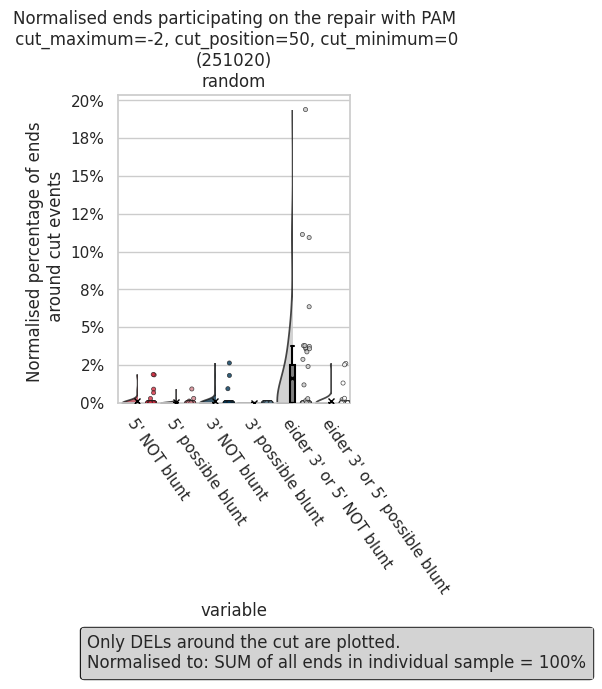

Statistic was saved as 05_01_DEL_end_summary_norm_violinplot_PAM_-2_50_0_stat.txt


In [8]:
# cut_maximum=-2
# cut_position=50
# cut_minimum=0

output_filename = f"../../CRISPRlysis_outputs/random_2025/random_sequences_grouped_{PAM}_{cut_maximum}_{cut_position}_{cut_minimum}_{date}.tsv"

columns_to_keep = [
    "Combination",
    "Gap_category_1",
    "Gap_category_2",
    "Cut_type",
    "End_participating_on_MH",
    "DEL_orientation",
    "End_3_5",
    "Likely_cut_type",
    "blunt_cut_with_MH_possible"
]

# Load the final DataFrame
final_df = pd.read_csv(output_filename, sep='\t')
# Get the number of iterations from the 'iteration' column
iterations = final_df['iteration'].max()

#  group by the 'Combination' column and sum the #Reads and divide it by the number of iterations (which is read from the 'iteration' column) and keep columns columns_to_keep
df_grouped = final_df.groupby(columns_to_keep)['#Reads'].agg(['sum']).reset_index()
df_grouped['%Reads'] = df_grouped['sum'] / iterations
# Normalise the '%Reads' column by dividing it by the column 'sum'
df_grouped['%Reads'] = 100*df_grouped['%Reads'] / df_grouped['%Reads'].sum()
# Sort by the '%Reads' column in descending order
df_grouped = df_grouped.sort_values(by='%Reads', ascending=False)
# Save the grouped DataFrame to a new file
output_filename = f"../../CRISPRlysis_outputs/random_2025/random_categories_grouped_norm_{PAM}_{cut_maximum}_{cut_position}_{cut_minimum}_{date}.tsv"
df_grouped.to_csv(output_filename, sep='\t', index=False)
print(f"Saved the grouped DataFrame to '{output_filename}'")
df_grouped.head()
df_grouped['End_3_5'] = df_grouped['End_3_5'].replace({3:'3\'', 5:'5\'', 0:'eider 3\' or 5\''})

pivot = pd.pivot_table(df_grouped, index=['Combination'], columns=['End_3_5', 'blunt_cut_with_MH_possible'], values='%Reads', aggfunc='sum', fill_value=0)
df_end_samples = pivot.reset_index()
# Flattern the MultiIndex columns
df_end_samples.columns = ['_'.join(map(str, col)).strip() for col in df_end_samples.columns.values]
# Rename columns
df_end_samples.rename(columns={'Combination_': 'Combination', '3\'_True':'3\' possible blunt', '5\'_True':'5\' possible blunt', 'eider 3\' or 5\'_True':'eider 3\' or 5\' possible blunt', '3\'_False':'3\' NOT blunt', '5\'_False':'5\' NOT blunt', 'eider 3\' or 5\'_False':'eider 3\' or 5\' NOT blunt'}, inplace=True)

df_end_samples, list_of_events = check_if_all_events_are_present_after_pivot_reset_index(df_end_samples, ['3\' possible blunt', '5\' possible blunt', 'eider 3\' or 5\' possible blunt', '3\' NOT blunt', '5\' NOT blunt', 'eider 3\' or 5\' NOT blunt'], cut_maximum, cut_minimum)

df_end_samples = pd.melt(df_end_samples, id_vars=['Combination'], value_vars=list_of_events)
#########################################################################################
# plot VIOLINPLOT
##########################################################################################
# NORMALISED
# Set charts properties for violinplot
title = f'Normalised ends participating on the repair with {PAM}\n cut_maximum={cut_maximum}, cut_position={cut_position}, cut_minimum={cut_minimum}'
ylabel = 'Normalised percentage of ends \n around cut events'
text_bellow_chart = f'Only DELs around the cut are plotted.\
                    \nNormalised to: SUM of all ends in individual sample = 100%'
name_to_save = f'05_01_DEL_end_summary_norm_violinplot_{PAM}_{cut_maximum}_{cut_position}_{cut_minimum}'
color_dic = get_color_dic_35_violin()
# TODO split it to True/False for can be blunt cut with MH
plot = plot_sns_violin_and_print(data=df_end_samples, x='variable', y='value'\
    , number_of_columns=3\
    , show_datapoints=True, jitter=0.1, stripplot_offset=10, dodge=False\
    , show_hue_medians=False\
    , hue=None, hue_only_for_data_points=False \
    , hatches=False\
    , clip_right=True\
    , title=title, xtickt_rotation=-55, ylabel=ylabel\
    , order=['5\' NOT blunt','5\' possible blunt', '3\' NOT blunt', '3\' possible blunt', 'eider 3\' or 5\' NOT blunt', 'eider 3\' or 5\' possible blunt']\
    , plot_legend=False\
    , integrated_properties_dic=False, color_dic=color_dic\
    , text_bellow_chart=text_bellow_chart\
    , y_legend_coordinate=-0.45, yaxis_formater=100\
    , x_max=None\
    , change_edge_color=False\
    , name_to_save=name_to_save\
    , project_output_dir=f"../../CRISPRlysis_outputs/random_2025"\
    , data_source='random', output_format='png'\
    , dpi=200, y_min=0, show_plots=True)
stat_info = df_end_samples.groupby('variable').value.describe()
save_stat(stat_info, name_to_save, f"../../CRISPRlysis_outputs/random_2025")

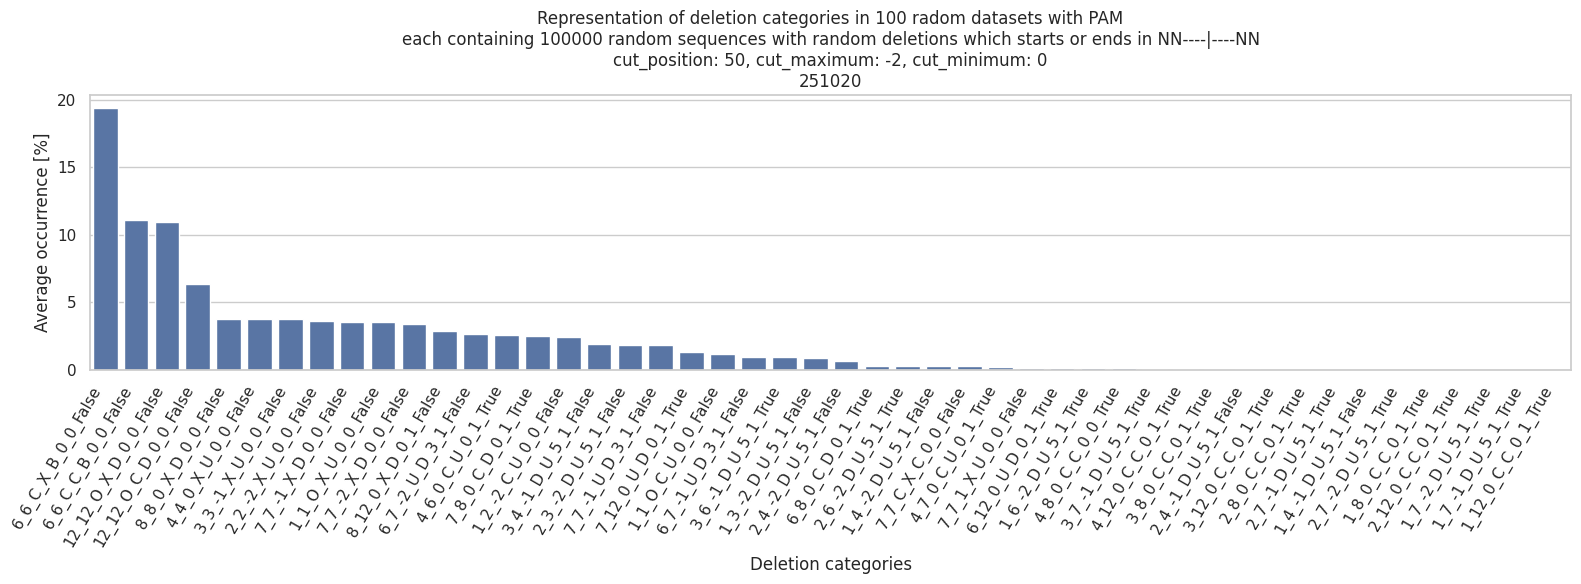

In [9]:
# Plot the Combination vs NormReads
## df_grouped['NormReads'] = df_grouped['sum'] / iterations
## df_grouped['NormReads'] = 100*df_grouped['NormReads'] / df_grouped['NormReads'].sum()

plt.figure(figsize=(df_grouped.shape[0]/3, 6))
sns.set_theme(style="whitegrid")
sns.barplot(x='Combination', y='%Reads', data=df_grouped)
plt.xticks(rotation=60, ha='right')
plt.xlabel('Deletion categories')
plt.ylabel('Average occurrence [%]')
plt.title(f'Representation of deletion categories in {iterations} radom datasets with {PAM}\neach containing {num_sequences} random sequences with random deletions which starts or ends in NN----|----NN\ncut_position: {cut_position}, cut_maximum: {cut_maximum}, cut_minimum: {cut_minimum}\n{date}')
plt.tight_layout()
plt.savefig(f'../../CRISPRlysis_outputs/random_2025/random_sequences_grouped_{PAM}_{cut_maximum}_{cut_position}_{cut_minimum}_{date}.png', dpi=300)
plt.show()


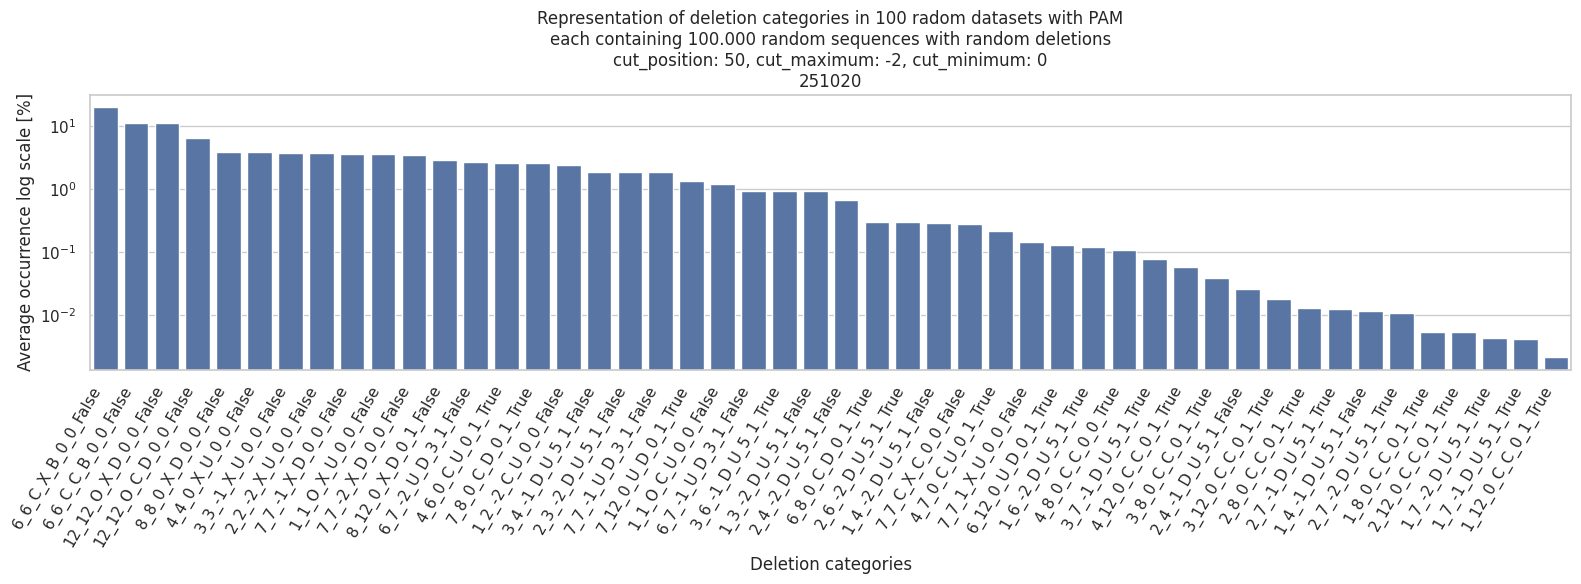

In [10]:
# Plot the Combination vs NormReads with log scale
plt.figure(figsize=(df_grouped.shape[0]/3, 6))
sns.set_theme(style="whitegrid")
sns.barplot(x='Combination', y='%Reads', data=df_grouped)
plt.xticks(rotation=60, ha='right')
plt.xlabel('Deletion categories')
plt.ylabel('Average occurrence log scale [%]')
plt.yscale('log')
plt.title(f'Representation of deletion categories in {iterations} radom datasets with {PAM}\neach containing 100.000 random sequences with random deletions\ncut_position: {cut_position}, cut_maximum: {cut_maximum}, cut_minimum: {cut_minimum}\n{date}')
plt.tight_layout()
plt.savefig(f'../../CRISPRlysis_outputs/random_2025/random_sequences_grouped_{PAM}_{cut_maximum}_{cut_position}_{cut_minimum}_log_{date}.png', dpi=300)
plt.show()